Step 1 – Load the dataset

In [10]:
import pandas as pd
import numpy as np

train = pd.read_csv("/content/test.csv")
test = pd.read_csv("/content/train.csv")

print("Training Shape:", train.shape)
print("Testing Shape:", test.shape)

print(train.head())
print(train.info())
print(train.describe())

Training Shape: (1459, 80)
Testing Shape: (1460, 81)
     Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0  1461          20       RH         80.0    11622   Pave   NaN      Reg   
1  1462          20       RL         81.0    14267   Pave   NaN      IR1   
2  1463          60       RL         74.0    13830   Pave   NaN      IR1   
3  1464          60       RL         78.0     9978   Pave   NaN      IR1   
4  1465         120       RL         43.0     5005   Pave   NaN      IR1   

  LandContour Utilities  ... ScreenPorch PoolArea PoolQC  Fence MiscFeature  \
0         Lvl    AllPub  ...         120        0    NaN  MnPrv         NaN   
1         Lvl    AllPub  ...           0        0    NaN    NaN        Gar2   
2         Lvl    AllPub  ...           0        0    NaN  MnPrv         NaN   
3         Lvl    AllPub  ...           0        0    NaN    NaN         NaN   
4         HLS    AllPub  ...         144        0    NaN    NaN         NaN   

  MiscVal MoSol

Step 2 – Understand missing values

In [11]:
missing = train.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

print(missing)

PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageQual        78
GarageCond        78
GarageYrBlt       78
GarageFinish      78
GarageType        76
BsmtCond          45
BsmtQual          44
BsmtExposure      44
BsmtFinType1      42
BsmtFinType2      42
MasVnrArea        15
MSZoning           4
Functional         2
BsmtFullBath       2
Utilities          2
BsmtHalfBath       2
Exterior1st        1
Exterior2nd        1
TotalBsmtSF        1
BsmtUnfSF          1
BsmtFinSF2         1
BsmtFinSF1         1
KitchenQual        1
GarageArea         1
GarageCars         1
SaleType           1
dtype: int64


Step 3 – Check duplicates

In [12]:
print("Duplicate Rows:", train.duplicated().sum())

Duplicate Rows: 0


# ***Exploratory Data Analysis (EDA)***

Analysis 1 – Sale price distribution

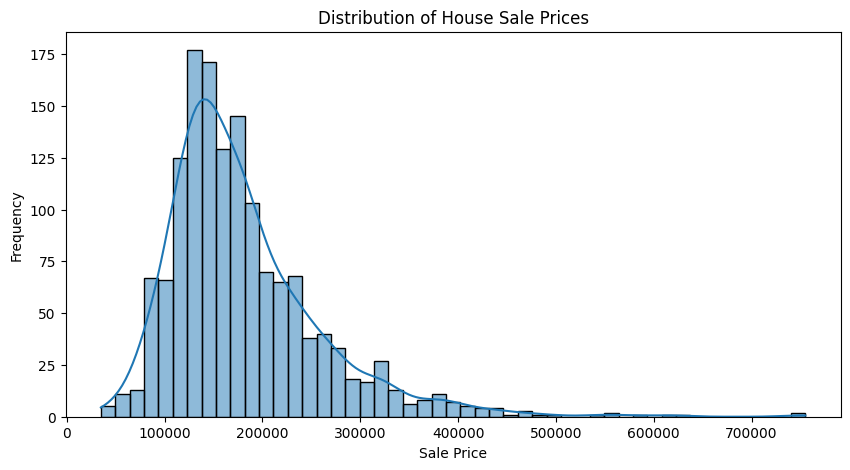

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# Using 'test' because the train and test DataFrames were swapped in Step 1
sns.histplot(
    test["SalePrice"],
    kde=True
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.savefig(
    "price_distribution.png"
)

plt.show()

Analysis 2 – House area vs selling price

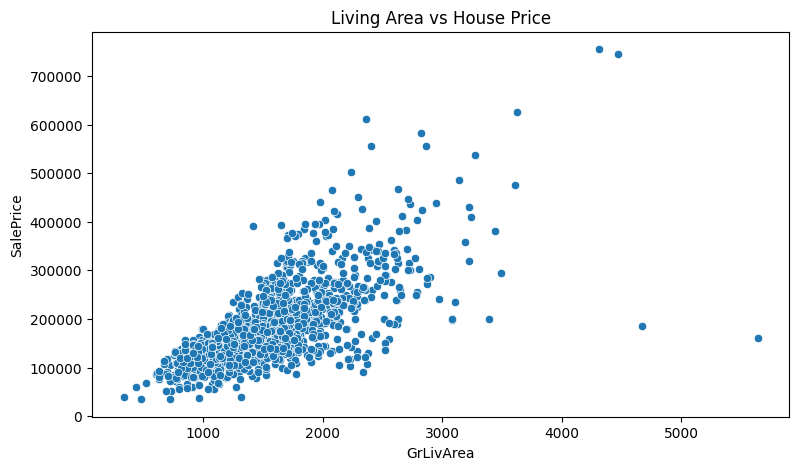

In [17]:
plt.figure(figsize=(9, 5))

# Using 'test' because the train and test DataFrames were swapped in Step 1
sns.scatterplot(
    data=test,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs House Price")
plt.savefig("price_vs_area.png")

plt.show()

Analysis 3 – Quality vs selling price

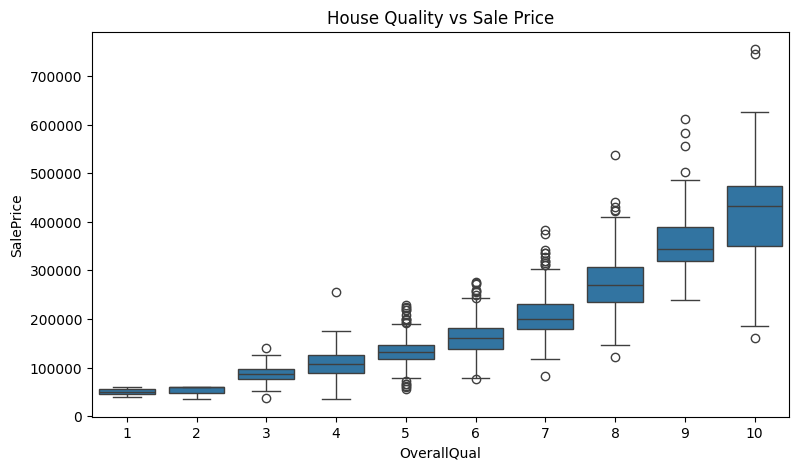

In [19]:
plt.figure(figsize=(9, 5))

# Using 'test' because the train and test DataFrames were swapped in Step 1
sns.boxplot(
    data=test,
    x="OverallQual",
    y="SalePrice"
)

plt.title("House Quality vs Sale Price")
plt.show()

Analysis 4 – Correlation heatmap

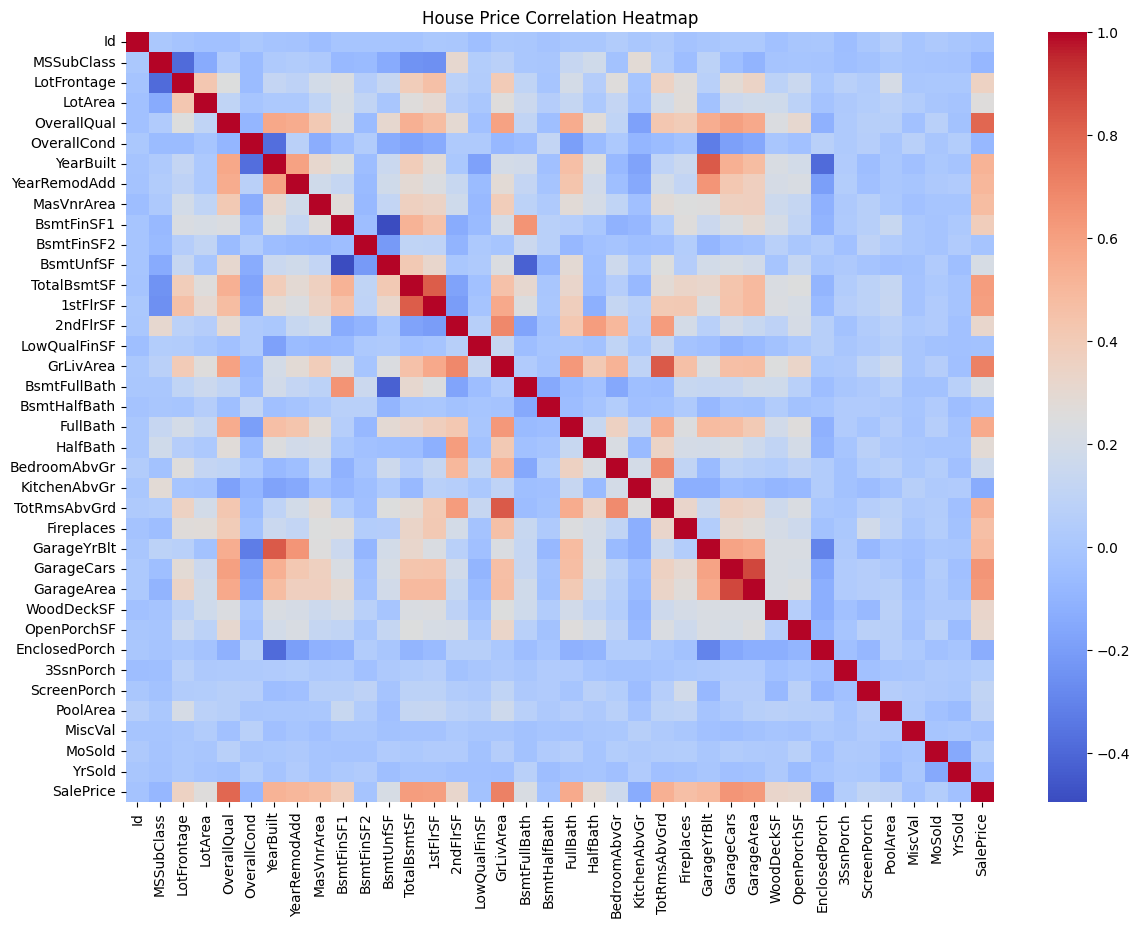

In [21]:
numeric_data = test.select_dtypes(
    include=np.number
)

correlation = numeric_data.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("House Price Correlation Heatmap")
plt.savefig("correlation_heatmap.png")

plt.show()

In [23]:
print("Dataset shape:", train.shape)

print("\nColumn names:")
print(train.columns.tolist())

print("\nFirst five rows:")
display(train.head())

Dataset shape: (1459, 80)

Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPo

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [24]:
import os

print(os.listdir("/content"))

['.config', 'price_distribution.png', 'correlation_heatmap.png', 'price_vs_area.png', '.ipynb_checkpoints', 'data_description.txt', 'sample_submission.csv', 'train.csv', 'test.csv', 'sample_data']


In [25]:
import pandas as pd

train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")

# Clean column names
train.columns = train.columns.str.strip()
test.columns = test.columns.str.strip()

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

print("SalePrice exists:", "SalePrice" in train.columns)

display(train.head())

Training shape: (1460, 81)
Testing shape: (1459, 80)
SalePrice exists: True


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# ***Data cleaning and preprocessingt***

Step 1 – Separate target and features

In [26]:
X = train.drop(columns=["SalePrice", "Id"])

y = train["SalePrice"]

test_ids = test["Id"]

X_test = test.drop(columns=["Id"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Test shape:", X_test.shape)

Features shape: (1460, 79)
Target shape: (1460,)
Test shape: (1459, 79)


Step 2 – Feature engineering

In [27]:
def create_features(df):

    df = df.copy()

    # Total house area
    df["TotalSF"] = (
        df["TotalBsmtSF"].fillna(0)
        + df["1stFlrSF"].fillna(0)
        + df["2ndFlrSF"].fillna(0)
    )

    # Total bathrooms
    df["TotalBathrooms"] = (
        df["FullBath"].fillna(0)
        + 0.5 * df["HalfBath"].fillna(0)
        + df["BsmtFullBath"].fillna(0)
        + 0.5 * df["BsmtHalfBath"].fillna(0)
    )

    # House age
    df["HouseAge"] = (
        df["YrSold"] - df["YearBuilt"]
    )

    # Years since remodeling
    df["YearsSinceRemodel"] = (
        df["YrSold"] - df["YearRemodAdd"]
    )

    # Total porch area
    df["TotalPorchSF"] = (
        df["WoodDeckSF"].fillna(0)
        + df["OpenPorchSF"].fillna(0)
        + df["EnclosedPorch"].fillna(0)
        + df["3SsnPorch"].fillna(0)
        + df["ScreenPorch"].fillna(0)
    )

    return df


X = create_features(X)
X_test = create_features(X_test)

print("Feature engineering completed!")
print("Training features:", X.shape)
print("Testing features:", X_test.shape)

Feature engineering completed!
Training features: (1460, 84)
Testing features: (1459, 84)


Step 3: Identify numerical and categorical features

In [28]:
# Identify numerical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Total Numerical Features:",
      len(numeric_features))

print("Total Categorical Features:",
      len(categorical_features))

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Total Numerical Features: 41
Total Categorical Features: 43

Numerical Features:
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'TotalSF', 'TotalBathrooms', 'HouseAge', 'YearsSinceRemodel', 'TotalPorchSF']

Categorical Features:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 

Step 4 – Missing value analysis

In [29]:
# Check missing values

missing_values = X.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

print("Features with missing values:")
display(missing_values)

print("\nTotal Missing Values:",
      X.isnull().sum().sum())

Features with missing values:


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81



Total Missing Values: 7829


# ***9. Split the datasett***

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (1168, 84)
Validation: (292, 84)


Transform the target variable

In [31]:
import numpy as np

y_train_log = np.log1p(y_train)

y_val_log = np.log1p(y_val)

print("Target transformation completed!")

print("Original target:")
print(y_train.head())

print("\nTransformed target:")
print(y_train_log.head())

Target transformation completed!
Original target:
254     145000
1066    178000
638      85000
799     175000
380     127000
Name: SalePrice, dtype: int64

Transformed target:
254     11.884496
1066    12.089544
638     11.350418
799     12.072547
380     11.751950
Name: SalePrice, dtype: float64


# ***10 – Machine learning model development***

Import models and evaluation metrics

In [32]:
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

Define machine learning models

In [33]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(
        alpha=10.0
    ),

    "Lasso Regression": Lasso(
        alpha=0.001,
        max_iter=20000
    )
}

print("Three models are ready!")

Three models are ready!


Train and evaluate all models

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
import numpy as np

# Define the preprocessing steps for both numerical and categorical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine preprocessors into a single ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train using log-transformed prices
    pipeline.fit(X_train, y_train_log)

    # Predict validation prices in log scale
    predictions_log = pipeline.predict(X_val)

    # Convert back to original prices
    predictions = np.expm1(predictions_log)

    predictions = np.maximum(predictions, 0)

    # Evaluation metrics
    mae = mean_absolute_error(
        y_val,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            predictions
        )
    )

    log_rmse = np.sqrt(
        mean_squared_error(
            y_val_log,
            predictions_log
        )
    )

    r2 = r2_score(
        y_val,
        predictions
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Log_RMSE": log_rmse,
        "R2_Score": r2
    })

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("Log RMSE:", round(log_rmse, 5))
    print("R2 Score:", round(r2, 4))


Model: Linear Regression
MAE: 14900.01
RMSE: 22741.0
Log RMSE: 0.12809
R2 Score: 0.9326

Model: Ridge Regression
MAE: 16404.42
RMSE: 25046.18
Log RMSE: 0.13614
R2 Score: 0.9182

Model: Lasso Regression
MAE: 16264.78
RMSE: 25047.79
Log RMSE: 0.13715
R2 Score: 0.9182


# ***11 – Compare model performance***

Create comparison table

In [36]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Log_RMSE"
).reset_index(drop=True)

display(results_df)

,Model,MAE,RMSE,Log_RMSE,R2_Score
0,Linear Regression,14900.013348,22741.000212,0.128087,0.932577
1,Ridge Regression,16404.421383,25046.179757,0.136144,0.918216
2,Lasso Regression,16264.776569,25047.786221,0.137154,0.918205


Visualize model comparison

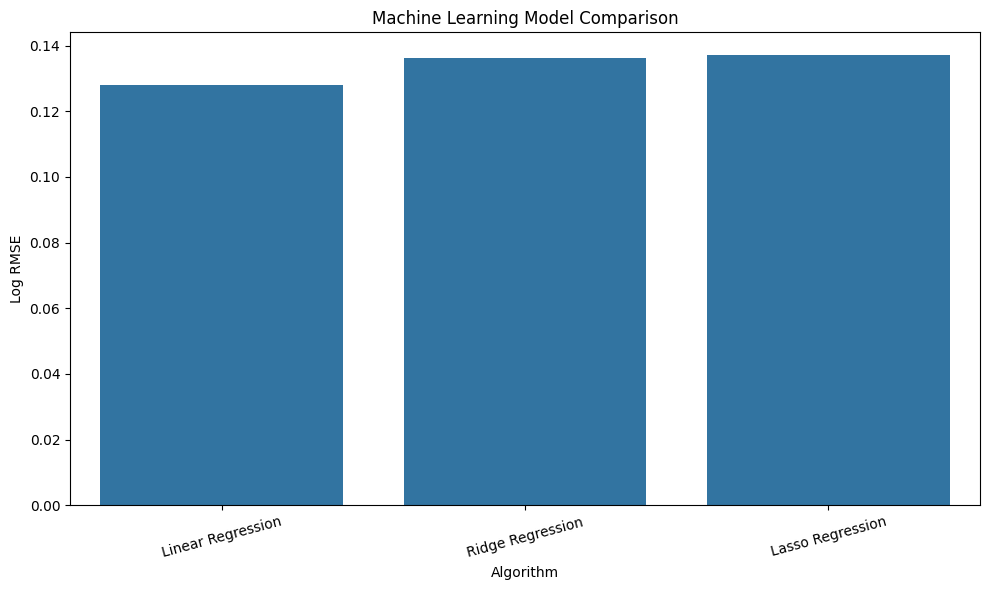

In [37]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Log_RMSE"
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Log RMSE")

plt.xticks(rotation=15)

plt.tight_layout()

plt.show()

Save comparison results

In [38]:
import os

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


# ***12 – Select the best modelt***

In [39]:
best_model_name = results_df.loc[0, "Model"]

best_model = trained_models[best_model_name]

print("BEST MODEL:", best_model_name)

print("\nBest model performance:")

display(
    results_df.iloc[[0]]
)

BEST MODEL: Linear Regression

Best model performance:


,Model,MAE,RMSE,Log_RMSE,R2_Score
0,Linear Regression,14900.013348,22741.000212,0.128087,0.932577


# **13 – Actual vs Predicted analysis**

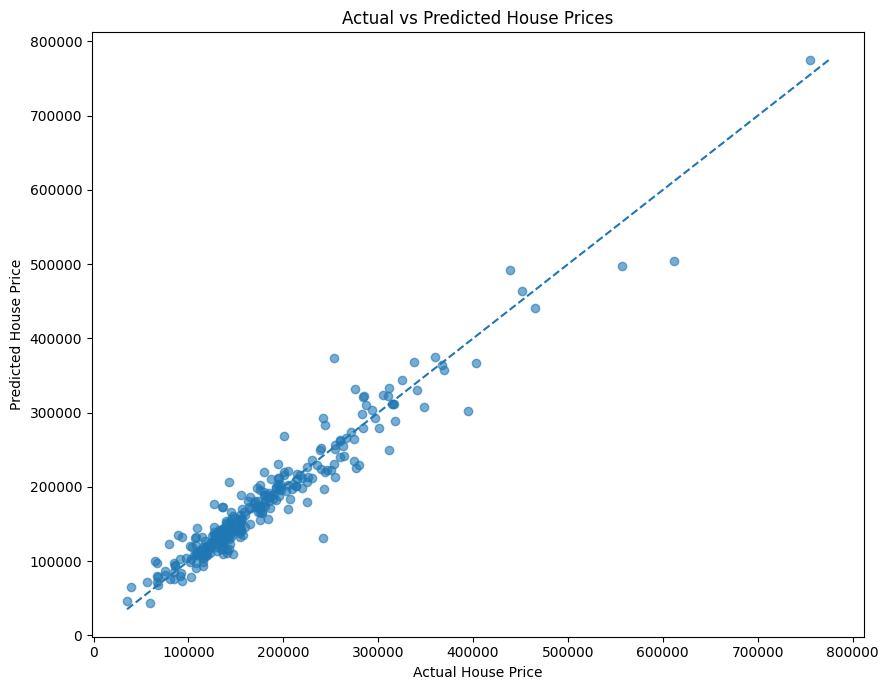

In [40]:
best_predictions_log = best_model.predict(X_val)

best_predictions = np.expm1(
    best_predictions_log
)

best_predictions = np.maximum(
    best_predictions, 0
)

plt.figure(figsize=(9, 7))

plt.scatter(
    y_val,
    best_predictions,
    alpha=0.6
)

min_price = min(y_val.min(), best_predictions.min())
max_price = max(y_val.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("Actual vs Predicted House Prices")

plt.tight_layout()

plt.savefig(
    "outputs/figures/actual_vs_predicted.png"
)

plt.show()

**14 – Residual analysist** *

Residual means:
\[
Residual = Actual - Predicted
\]

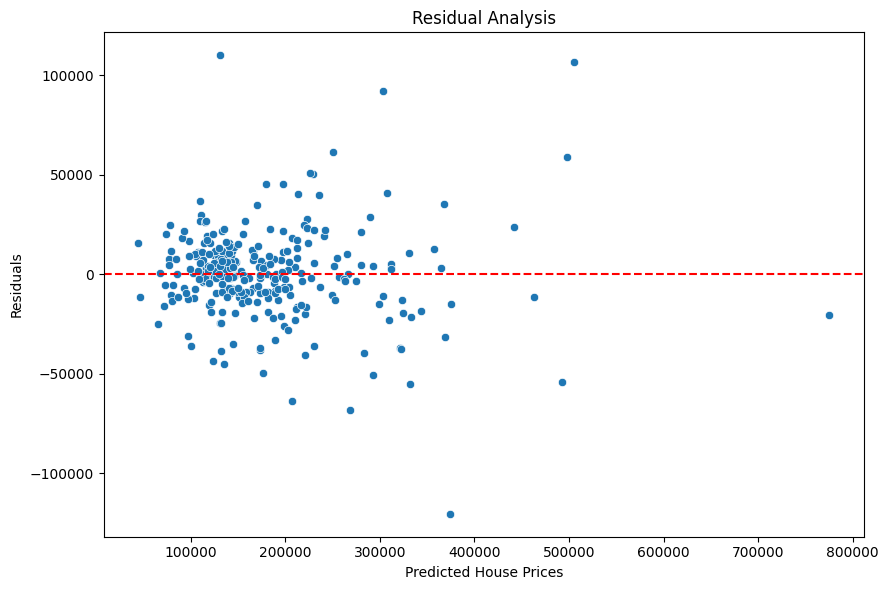

In [41]:
residuals = y_val - best_predictions

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=best_predictions,
    y=residuals
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")

plt.title("Residual Analysis")

plt.tight_layout()

plt.savefig(
    "outputs/figures/residual_plot.png"
)

plt.show()

# **15 – Feature importance analysis**

In [42]:
fitted_preprocessor = best_model.named_steps["preprocessor"]

fitted_estimator = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

coefficients = fitted_estimator.coef_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by="Absolute_Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Coefficient,Absolute_Importance
129,cat__RoofMatl_ClyTile,-2.413940,2.413940
106,cat__Condition2_PosN,-0.758938,0.758938
131,cat__RoofMatl_Metal,0.488659,0.488659
132,cat__RoofMatl_Roll,0.439172,0.439172
107,cat__Condition2_RRAe,-0.393167,0.393167
135,cat__RoofMatl_WdShngl,0.386131,0.386131
134,cat__RoofMatl_WdShake,0.375945,0.375945
130,cat__RoofMatl_CompShg,0.368535,0.368535
133,cat__RoofMatl_Tar&Grv,0.355498,0.355498
103,cat__Condition2_Feedr,0.355316,0.355316


Visualize important features

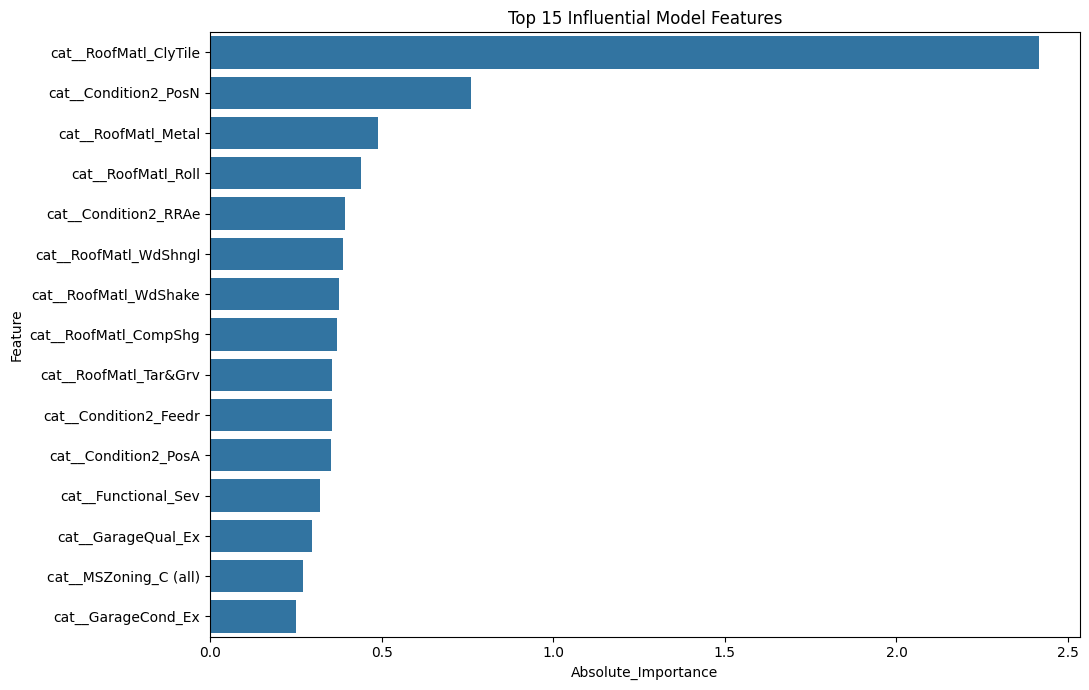

In [43]:
top_features = feature_importance.head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_features,
    x="Absolute_Importance",
    y="Feature"
)

plt.title("Top 15 Influential Model Features")

plt.tight_layout()

plt.savefig(
    "outputs/figures/feature_importance.png"
)

plt.show()

# ***16 – Train the final model***

In [44]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", models[best_model_name])
])

final_model.fit(
    X,
    np.log1p(y)
)

print("Final model trained successfully!")
print("Selected algorithm:", best_model_name)

Final model trained successfully!
Selected algorithm: Linear Regression


# ***17 – Generate house price predictions***

In [45]:
test_predictions_log = final_model.predict(X_test)

test_predictions = np.expm1(
    test_predictions_log
)

test_predictions = np.maximum(
    test_predictions,
    0
)

print("Predictions generated successfully!")

print("Total predictions:", len(test_predictions))

print("First 10 predictions:")

print(test_predictions[:10])

Predictions generated successfully!
Total predictions: 1459
First 10 predictions:
[122479.59709338 166302.66860052 184696.30852378 201054.2435884
 195457.85435375 171699.32208514 180139.09780317 162315.78946918
 194532.63745755 121887.05306204]


# ***18 – Generate Kaggle submission file***

In [46]:
submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": test_predictions
})

submission.to_csv(
    "outputs/submission.csv",
    index=False
)

print("Submission file created!")

display(submission.head())

Submission file created!


,Id,SalePrice
0,1461,122479.597093
1,1462,166302.668601
2,1463,184696.308524
3,1464,201054.243588
4,1465,195457.854354


In [47]:
print("Submission shape:", submission.shape)

print("Missing values:")
print(submission.isnull().sum())

print("Duplicate IDs:")
print(submission["Id"].duplicated().sum())

assert list(submission.columns) == ["Id", "SalePrice"]
assert len(submission) == len(test)
assert submission["SalePrice"].notna().all()
assert (submission["SalePrice"] >= 0).all()

print("\nSubmission validation successful!")

Submission shape: (1459, 2)
Missing values:
Id           0
SalePrice    0
dtype: int64
Duplicate IDs:
0

Submission validation successful!


# ***9 – Save the trained machine learning model***

In [48]:
import joblib

joblib.dump(
    final_model,
    "models/best_house_price_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


Load and verify saved model

In [49]:
loaded_model = joblib.load(
    "models/best_house_price_model.pkl"
)

sample_predictions = np.expm1(
    loaded_model.predict(X_test.head(5))
)

print("Loaded model successfully!")

print("Sample predictions:")
print(sample_predictions)

Loaded model successfully!
Sample predictions:
[122479.59709338 166302.66860052 184696.30852378 201054.2435884
 195457.85435375]


# ***20 – Create a reusable prediction function***

In [50]:
def predict_house_price(new_data):

    new_data = create_features(new_data)

    prediction_log = final_model.predict(new_data)

    prediction = np.expm1(prediction_log)

    return np.maximum(prediction, 0)


# Test with an existing test record

sample_house = test.drop(columns=["Id"]).head(1)

predicted_price = predict_house_price(sample_house)

print(
    "Predicted House Price:",
    round(float(predicted_price[0]), 2)
)

Predicted House Price: 122479.6
